In [2]:
import os, sys
env = os.path.dirname(sys.executable)
os.environ['PATH'] = os.pathsep.join([
    env, rf'{env}\Library\bin', rf'{env}\Library\mingw-w64\bin',
    rf'{env}\Library\usr\bin', rf'{env}\Scripts', os.environ['PATH']])
os.environ['OMP_NUM_THREADS'] = '1'

In [3]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path(r'c:\Users\bhowm\Downloads\Yelp-JSON')
data = pd.read_pickle(ROOT / 'data/02_processed/restaurant_features.pkl')
dev = data.loc[data.split.eq('development')].copy()   # holdout stays untouched
print(data.shape, dev.shape)

(52268, 25) (41802, 25)


In [4]:
labels = ['Low', 'Medium', 'High']
dev['rating_class'] = pd.cut(dev.stars, bins=[0, 2.5, 3.5, 5], labels=labels)   # (0,2.5], (2.5,3.5], (3.5,5]
y = dev['rating_class'].astype(str)
print(y.value_counts(normalize=True).reindex(labels).round(3))

numeric = ['latitude', 'longitude', 'category_count', 'listed_days', 'weekly_listed_hours']
categorical = ['state', 'city_state', 'price_range', 'takeout', 'delivery',
               'outdoor_seating', 'reservations', 'alcohol', 'wifi', 'noise_level']
X = dev[numeric + categorical].copy()
for c in categorical:
    X[c] = X[c].astype(object).where(X[c].notna(), 'Unknown')

def make_pre():
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                          ('scale', StandardScaler())]), numeric),
        ('cat', OneHotEncoder(min_frequency=100, handle_unknown='infrequent_if_exist',
                              sparse_output=False), categorical),
    ])

def make_model(**kw):
    return Pipeline([('pre', make_pre()),
                     ('clf', LogisticRegression(max_iter=2000, C=1.0, **kw))])

models = {
    'Majority-class baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_model(),
    'Logistic regression (balanced weights)': make_model(class_weight='balanced'),
}

rating_class
Low       0.182
Medium    0.371
High      0.448
Name: proportion, dtype: float64


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=6021)
scoring = {'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy',
           'macro_F1': 'f1_macro', 'log_loss': 'neg_log_loss'}

rows = []
for name, est in models.items():
    res = cross_validate(est, X, y, cv=cv, scoring=scoring)
    rows.append({'model': name,
                 'accuracy': res['test_accuracy'].mean(),
                 'balanced_accuracy': res['test_balanced_accuracy'].mean(),
                 'macro_F1': res['test_macro_F1'].mean(),
                 'log_loss': -res['test_log_loss'].mean()})
results = pd.DataFrame(rows).set_index('model')
results.round(3)

,accuracy,balanced_accuracy,macro_F1,log_loss
model,,,,
Majority-class baseline,0.448,0.333,0.206,19.914
Logistic regression,0.566,0.523,0.533,0.899
Logistic regression (balanced weights),0.532,0.550,0.520,0.945


              precision    recall  f1-score   support

         Low      0.571     0.373     0.451      7588
      Medium      0.503     0.477     0.490     15507
        High      0.608     0.719     0.658     18707

    accuracy                          0.566     41802
   macro avg      0.560     0.523     0.533     41802
weighted avg      0.562     0.566     0.558     41802



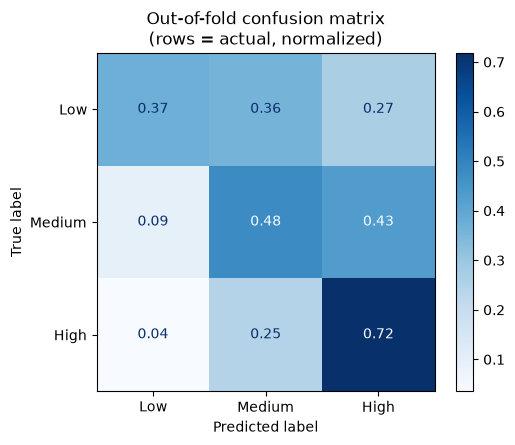

In [6]:
best = models['Logistic regression']
pred = cross_val_predict(best, X, y, cv=cv)          # out-of-fold predictions
print(classification_report(y, pred, labels=labels, digits=3))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=labels, normalize='true',
                                        values_format='.2f', cmap='Blues', ax=ax)
ax.set_title('Out-of-fold confusion matrix\n(rows = actual, normalized)')
plt.tight_layout(); plt.show()

In [7]:
best.fit(X, y)
names = best.named_steps['pre'].get_feature_names_out()
coef = pd.DataFrame(best.named_steps['clf'].coef_, index=best.named_steps['clf'].classes_, columns=names).T
for cls in ['High', 'Low']:
    print(f'\nTop drivers toward {cls}:')
    print(coef[cls].sort_values(ascending=False).head(8).round(3))


Top drivers toward High:
cat__alcohol_beer_and_wine         0.467
cat__noise_level_quiet             0.413
cat__price_range_Unknown           0.381
cat__city_state_Dunedin, FL        0.371
cat__city_state_New Orleans, LA    0.366
cat__noise_level_average           0.314
cat__city_state_Fishers, IN        0.310
cat__noise_level_nan               0.262
Name: High, dtype: float64

Top drivers toward Low:
cat__noise_level_very_loud          0.654
cat__city_state_Exton, PA           0.560
cat__city_state_Phoenixville, PA    0.457
num__weekly_listed_hours            0.448
cat__city_state_Newark, DE          0.414
cat__city_state_Kenner, LA          0.365
cat__city_state_Pottstown, PA       0.359
cat__city_state_Bensalem, PA        0.340
Name: Low, dtype: float64


In [8]:
OUT = ROOT / 'reports/models'
OUT.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT / 'model2_multiclass_logistic_cv.csv')
coef.to_csv(OUT / 'model2_coefficients.csv')

In [8]:
from sklearn.linear_model import LogisticRegression
actionable = ['price_range', 'takeout', 'delivery', 'outdoor_seating', 'reservations',
              'alcohol', 'wifi', 'noise_level']
y_high = (dev.stars >= 4).astype(int)

pre_hi = make_pre()
clf = Pipeline([('pre', pre_hi), ('clf', LogisticRegression(max_iter=2000))]).fit(X, y_high)
names = pre_hi.get_feature_names_out()
odds = pd.Series(np.exp(clf.named_steps['clf'].coef_[0]), index=names)
odds = odds[[n for n in odds.index if any(n.startswith(f'cat__{a}_') for a in actionable)]]
print(odds.sort_values(ascending=False).round(2))

cat__alcohol_beer_and_wine      1.64
cat__price_range_Unknown        1.64
cat__noise_level_quiet          1.60
cat__noise_level_average        1.43
cat__noise_level_nan            1.37
cat__wifi_free                  1.24
cat__delivery_Unknown           1.22
cat__outdoor_seating_Unknown    1.19
cat__wifi_no                    1.12
cat__reservations_Unknown       1.11
cat__takeout_Yes                1.09
cat__alcohol_none               1.08
cat__outdoor_seating_Yes        0.99
cat__delivery_No                0.98
cat__takeout_Unknown            0.98
cat__price_range_4              0.94
cat__reservations_Yes           0.93
cat__price_range_3              0.87
cat__price_range_2              0.84
cat__reservations_No            0.83
cat__takeout_No                 0.80
cat__wifi_paid                  0.79
cat__wifi_nan                   0.78
cat__price_range_1              0.76
cat__alcohol_nan                0.74
cat__outdoor_seating_No         0.73
cat__noise_level_loud           0.72
c